# Outcome calibration (delivery plan, step 1.16)

Baseline arm, no agents, seed 42, 365 days. Target: 30-day HF readmission inside the PNE range, about 12% ATS-wide and 10–16% per hospital (`src/sim/README.md` §4). Parameters: `src/sim/config/baseline.json`.

Re-run: `uv run jupyter nbconvert --to notebook --execute --inplace testing/notebooks/calibration.ipynb`

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from sim.calibration import HOSPITAL_RANGE, TARGET_READMISSION, readmissions, simulate
from sim.population import generate_patients, load_reference
from sim.step import load_params

ref = load_reference()
results, events = {}, {}
for seed in (42, 7, 2026):
    patients = generate_patients(seed, ref)[0]
    events[seed] = simulate(seed, world=(ref, patients))
    results[seed] = readmissions(events[seed])
pd.DataFrame({s: {'readmission_30d': r['rate'], **r['by_hospital'], 'discharges': r['discharges'],
                  'discharges_per_patient_year': r['discharges_per_patient_year']} for s, r in results.items()}).round(4)

,42,7,2026
readmission_30d,0.1200,0.1145,0.1196
osp_A,0.1223,0.1213,0.1168
osp_B,0.1167,0.1047,0.1315
osp_C,0.1186,0.1091,0.1117
discharges,3041.0000,3030.0000,2967.0000
discharges_per_patient_year,0.3302,0.3327,0.3260


## 30-day readmission against the PNE range

The band is the calibration range per hospital; the dashed line is the ATS target. Three seeds show the noise of one simulated year.

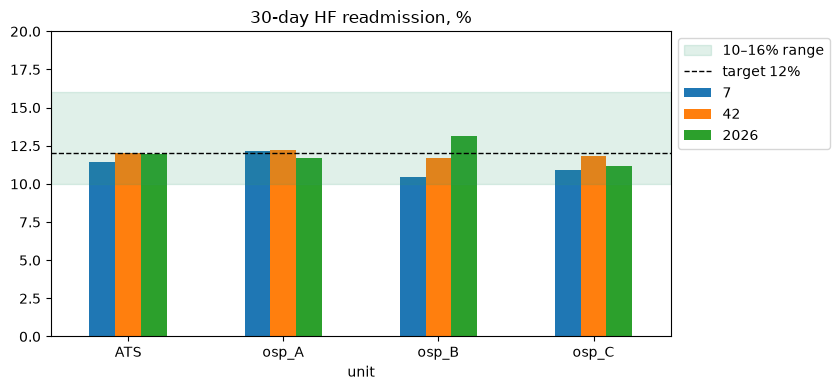

In [2]:
rows = [(s, h, v) for s, r in results.items() for h, v in {'ATS': r['rate'], **r['by_hospital']}.items()]
df = pd.DataFrame(rows, columns=['seed', 'unit', 'rate']).pivot(index='unit', columns='seed', values='rate')
ax = (df * 100).plot.bar(figsize=(8.5, 4), rot=0, title='30-day HF readmission, %')
ax.axhspan(HOSPITAL_RANGE[0] * 100, HOSPITAL_RANGE[1] * 100, color='#2f9e6e', alpha=0.15, label='10–16% range')
ax.axhline(TARGET_READMISSION * 100, color='k', ls='--', lw=1, label='target 12%')
ax.set_ylim(0, 20); ax.legend(loc='upper left', bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

## Risk factors move admissions the right way

Admissions per patient-year in the baseline arm, seed 42.

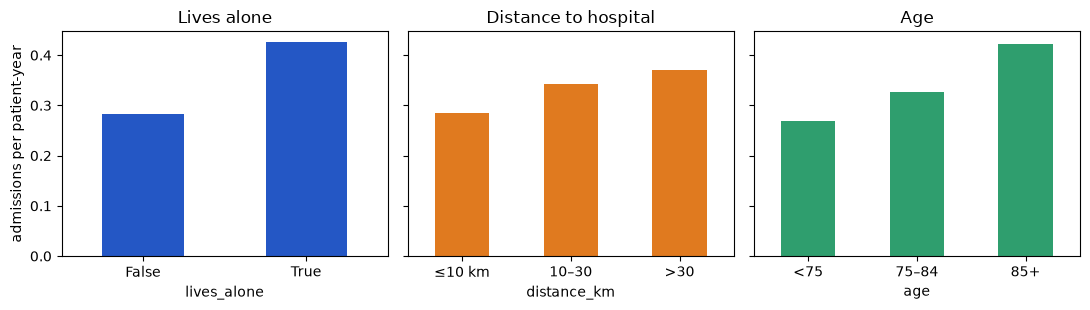

In [3]:
ev, patients = events[42], generate_patients(42, ref)[0]
adm = ev[(ev.event_type == 'ADMISSION') & (ev.day >= 0)].groupby('patient_id').size()
p = patients.set_index('patient_id').assign(admissions=lambda d: d.index.map(adm).fillna(0))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
p.groupby('lives_alone').admissions.mean().plot.bar(ax=axes[0], rot=0, title='Lives alone', color='#2457c5')
p.groupby(pd.cut(p.distance_km, [-1, 10, 30, 70], labels=['≤10 km', '10–30', '>30'])).admissions.mean().plot.bar(ax=axes[1], rot=0, title='Distance to hospital', color='#e07a1f')
p.groupby(pd.cut(p.age, [0, 75, 85, 120], labels=['<75', '75–84', '85+'])).admissions.mean().plot.bar(ax=axes[2], rot=0, title='Age', color='#2f9e6e')
axes[0].set_ylabel('admissions per patient-year'); plt.tight_layout(); plt.show()

## Weight rises before an admission

Telemonitored weight relative to the patient's median, by days before admission. The rule `weight_gain_kg_3d >= 2` in the pathway sees this.

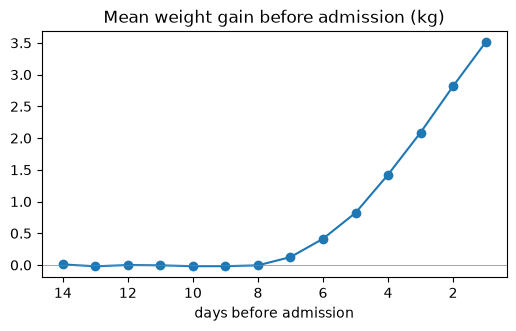

In [4]:
rd = ev[ev.event_type == 'TELEMON_READING'][['patient_id', 'day', 'value']]
ad = ev[ev.event_type == 'ADMISSION'][['patient_id', 'day']].rename(columns={'day': 'adm'})
m = rd.merge(ad, on='patient_id')
m = m[(m.adm - m.day).between(1, 14)]
m['gain'] = m.value - m.patient_id.map(rd.groupby('patient_id').value.median())
curve = m.groupby(m.adm - m.day).gain.mean().sort_index(ascending=False)
ax = curve.plot(marker='o', figsize=(6, 3.2), title='Mean weight gain before admission (kg)')
ax.invert_xaxis(); ax.set_xlabel('days before admission'); ax.axhline(0, color='grey', lw=0.5); plt.show()

## Parameters

In [5]:
params = load_params()
pd.Series({k: v for k, v in params.model_dump().items() if not isinstance(v, dict)}).to_frame('value')

,value
warmup_days,120
admission_daily,0.000561
post_discharge_multiplier,5.47
post_discharge_days,30
los_mean,8.0
discharge_code,428.0
decomp_days_min,3
decomp_days_max,7
decomp_weight_gain_kg_per_day,0.7
p_book,0.85
